<a href="https://colab.research.google.com/github/subhashraj3031/AlmaBetter_Project/blob/main/Predicting_Shopzilla_Customer_Satisfaction_with_an_ANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project Name** — Predicting Shopzilla Customer Satisfaction with an ANN

##### **Project Type** — Deep Learning / Multiclass Classification
##### **Contribution** — Individual
##### **Author** — Subhash Puri

# **Project Summary -**

This project develops a reproducible artificial neural network to predict customer satisfaction scores for Shopzilla customer support interactions. The dataset contains 85,907 records and twenty columns describing service channels, interaction categories, timestamps, order information, staffing context, customer feedback and a satisfaction score from one to five. The intended prediction time is the end of the service interaction, before a customer completes the satisfaction survey. This boundary determines which features can legitimately be used and prevents information collected after the outcome from creating misleading performance estimates.

The analysis begins with a systematic integrity audit covering column types, missingness, repeated records, record identifiers and target validity. Several business fields are incomplete, so missing observations are retained through explicit categorical markers, numerical imputation and missingness indicators. Response delay is derived from the reported and responded timestamps, while report hour and weekday capture operational timing. Customer remarks and survey timestamps are excluded from training because the timing of feedback collection is uncertain and the text may directly reveal the satisfaction score. Identifiers and staff names are also excluded to limit memorization and unnecessary exposure of personal information.

Exploratory analysis follows the supplied template through fifteen charts covering class balance, service demand, operational groups, missingness, numerical distributions and relationships with satisfaction. Each chart includes the reason for choosing it, the observed result and a possible business application with limitations. Three permutation tests examine differences in satisfaction across channels, categories and shifts. These tests describe associations in the available records; they do not establish that changing a channel or staffing practice would cause satisfaction to improve. Multiple comparisons and the large sample size require attention to effect sizes as well as statistical significance.

Data is divided into stratified training, validation and test partitions using a fixed random seed. All model preprocessing is fitted on training records only. Numerical variables receive median imputation, logarithmic transformation where appropriate and standardization. Categorical variables receive one-hot encoding with a reserved position for previously unseen values. The neural network uses a fully connected hidden layer containing sixty-four ReLU units and a five-class softmax output. It is implemented directly in NumPy with backpropagation, Adam optimization, L2 regularization, mini-batches and early stopping based on validation loss. Additional experiments compare a smaller architecture and class-weighted training using validation results.

The original sixty-four-unit model achieved 69.58 percent accuracy on the held-out test set. However, predicting the majority score alone achieved 69.39 percent, making the improvement small. Macro F1 was approximately 0.188 and recall for scores two, three and four was zero. These findings show why accuracy alone cannot establish useful customer service performance. The notebook reports the confusion matrix, class recalls, balanced accuracy and absolute score error to make this weakness visible. Permutation importance suggests response delay and interaction subcategory contribute to predictions, although their effects are small and correlated inputs complicate interpretation.

The project includes saved preprocessing and weights, a local batch prediction demonstration, reproducible training code and presentation guidance. The deployment returns predicted scores, expected scores and probabilities, but should be treated as an educational prototype. Practical next steps include chronological and grouped validation, stronger ordinal objectives, better minority-class modeling, probability calibration and collection of reliable pre-survey interaction features. Human review remains essential when using these predictions to prioritize service improvement.

# **GitHub Link -**

A remote GitHub repository has not been supplied. All source files are included in the project package; repository URL and actual commit history must be added after publication.

# **Problem Statement**


Predict CSAT scores 1–5 from information available at the end of a support interaction. Compare an ANN with a majority baseline, report class-sensitive metrics, identify operational associations and demonstrate local inference. Course grading is separate from predictive accuracy.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
import os, sys, json, pickle
from pathlib import Path
import numpy as np
import pandas as pd
try:
    from IPython.display import display, SVG
except ImportError:
    def display(obj): print(obj)
    def SVG(text): return text
"""Reproducible NumPy ANN capstone. Run: python csat_capstone.py --data PATH"""
from pathlib import Path
import argparse, json, pickle, time
import numpy as np
import pandas as pd

SEED=42
CAT=['channel_name','category','Sub-category','Product_category','Tenure Bucket','Agent Shift']
NUM=['Item_price','connected_handling_time','response_minutes','report_hour','report_weekday']

def features(df):
    x=df.copy()
    for c in CAT: x[c]=x.get(c,pd.Series(index=x.index,dtype=str)).fillna('Missing').astype(str).str.strip().replace('', 'Missing')
    for c in ['Item_price','connected_handling_time']: x[c]=pd.to_numeric(x.get(c,pd.Series(index=x.index,dtype=float)),errors='coerce').clip(lower=0)
    t=pd.to_datetime(x.get('Issue_reported at'),format='%d/%m/%Y %H:%M',errors='coerce')
    r=pd.to_datetime(x.get('issue_responded'),format='%d/%m/%Y %H:%M',errors='coerce')
    x['response_minutes']=(r-t).dt.total_seconds().div(60).where(lambda s:s>=0)
    x['report_hour']=t.dt.hour; x['report_weekday']=t.dt.dayofweek
    return x[CAT+NUM]

def fit_preprocessor(x):
    return {'vocab':{c:sorted(x[c].unique().tolist()) for c in CAT},'median':x[NUM].median().fillna(0).to_numpy(), 'mean':None,'std':None}

def transform(x,p,fit=False):
    n=x[NUM].to_numpy(dtype=float); missing=np.isnan(n).astype(float)
    n=np.where(np.isnan(n),p['median'],n)
    n[:,:3]=np.log1p(n[:,:3])
    if fit: p['mean']=n.mean(0); p['std']=np.maximum(n.std(0),1e-6)
    blocks=[np.clip((n-p['mean'])/p['std'],-8,8),missing]
    for c,v in p['vocab'].items():
        lookup={s:i for i,s in enumerate(v)}; ids=np.array([lookup.get(s,len(v)) for s in x[c]])
        blocks.append(np.eye(len(v)+1,dtype=np.float32)[ids])
    return np.concatenate(blocks,axis=1).astype(np.float32)

def forward(x,w):
    h=np.maximum(x@w['w1']+w['b1'],0); z=h@w['w2']+w['b2']; z-=z.max(1,keepdims=True)
    p=np.exp(z); return h,p/p.sum(1,keepdims=True)

def metrics(y,p):
    pred=p.argmax(1); cm=np.zeros((5,5),int); np.add.at(cm,(y,pred),1)
    precision=np.diag(cm)/np.maximum(cm.sum(0),1); recall=np.diag(cm)/np.maximum(cm.sum(1),1)
    f1=2*precision*recall/np.maximum(precision+recall,1e-12)
    return {'accuracy':float((pred==y).mean()),'macro_f1':float(f1.mean()),'balanced_accuracy':float(recall.mean()),'mae':float(np.abs(pred-y).mean()),'expected_score_mae':float(np.abs(p@np.arange(1,6)-(y+1)).mean()),'confusion_matrix':cm.tolist(),'per_class_recall':recall.tolist()}

def main(data):
    start=time.time(); out=Path(__file__).parent; rng=np.random.default_rng(SEED)
    raw=pd.read_csv(data); audit={'rows_raw':len(raw),'missing_percent':(raw.isna().mean()*100).round(2).to_dict(),'exact_duplicates':int(raw.duplicated().sum()),'duplicate_ids':int(raw['Unique id'].duplicated().sum())}
    df=raw.drop_duplicates().drop_duplicates('Unique id').copy(); target=pd.to_numeric(df['CSAT Score'],errors='coerce'); df=df.loc[target.isin(range(1,6))].reset_index(drop=True)
    y=df['CSAT Score'].astype(int).to_numpy()-1; x=features(df)
    # Stratify 70/15/15. All fitting occurs only on training records.
    train=[]; val=[]; test=[]
    for k in range(5):
        ids=rng.permutation(np.where(y==k)[0]); a=int(.7*len(ids)); b=int(.85*len(ids)); train.extend(ids[:a]); val.extend(ids[a:b]); test.extend(ids[b:])
    train=np.array(train); val=np.array(val); test=np.array(test)
    p=fit_preprocessor(x.iloc[train]); X=transform(x,p,True)
    w={'w1':rng.normal(0,np.sqrt(2/X.shape[1]),(X.shape[1],64)).astype('f'),'b1':np.zeros(64,dtype='f'),'w2':rng.normal(0,np.sqrt(2/64),(64,5)).astype('f'),'b2':np.zeros(5,dtype='f')}
    m={k:np.zeros_like(v) for k,v in w.items()}; v={k:np.zeros_like(z) for k,z in w.items()}; history=[]; best=1e9; stale=0; step=0
    for epoch in range(60):
        for ids in np.array_split(rng.permutation(train),max(1,len(train)//256)):
            a=X[ids]; h,prob=forward(a,w); d=prob.copy(); d[np.arange(len(ids)),y[ids]]-=1; d/=len(ids)
            dh=(d@w['w2'].T)*(h>0)
            g={'w2':h.T@d+1e-4*w['w2'],'b2':d.sum(0),'w1':a.T@dh+1e-4*w['w1'],'b1':dh.sum(0)}; step+=1
            lr=.001*(.5**(epoch//15))
            for k in w:
                m[k]=.9*m[k]+.1*g[k]; v[k]=.999*v[k]+.001*g[k]**2
                w[k]-=lr*(m[k]/(1-.9**step))/(np.sqrt(v[k]/(1-.999**step))+1e-8)
        _,pv=forward(X[val],w); loss=float(-np.log(pv[np.arange(len(val)),y[val]]+1e-9).mean()); history.append({'epoch':epoch+1,'validation_loss':loss,'validation_accuracy':float((pv.argmax(1)==y[val]).mean())})
        print(history[-1],flush=True)
        if loss<best-1e-4: best=loss; bestw={k:z.copy() for k,z in w.items()}; stale=0
        else: stale+=1
        if stale>=7: break
    w=bestw; _,pt=forward(X[test],w); prior=np.bincount(y[train],minlength=5)/len(train); baseline=np.tile(prior,(len(test),1))
    result={'ann':metrics(y[test],pt),'majority_baseline':metrics(y[test],baseline),'split_sizes':{'train':len(train),'validation':len(val),'test':len(test)},'epochs':len(history),'best_epoch':min(history,key=lambda z:z['validation_loss'])['epoch'],'seed':SEED}
    importance={}
    for c in CAT+NUM:
        xp=x.iloc[test].copy(); xp[c]=rng.permutation(xp[c].to_numpy()); _,pp=forward(transform(xp,p),w); importance[c]=result['ann']['accuracy']-metrics(y[test],pp)['accuracy']
    result['permutation_accuracy_drop']=importance; result['seconds']=time.time()-start
    audit['rows_clean']=len(df); audit['target_counts']=df['CSAT Score'].value_counts().sort_index().to_dict()
    (out/'metrics.json').write_text(json.dumps(result,indent=2)); (out/'data_audit.json').write_text(json.dumps(audit,indent=2)); pd.DataFrame(history).to_csv(out/'training_history.csv',index=False)
    with (out/'model.pkl').open('wb') as f: pickle.dump({'weights':w,'preprocessor':p},f)
    pd.DataFrame({'actual':y[test]+1,'predicted':pt.argmax(1)+1,'expected_score':pt@np.arange(1,6)}).to_csv(out/'test_predictions.csv',index=False)
    groups=df.groupby('category')['CSAT Score'].agg(['count','mean']).sort_values('mean'); groups.to_csv(out/'category_insights.csv')
    df.iloc[test[:5]].drop(columns=['CSAT Score','Customer Remarks','Unique id','Order_id','Agent_name','Supervisor','Manager','Customer_City','Survey_response_Date'],errors='ignore').to_csv(out/'sample_input.csv',index=False)
    print(json.dumps(result,indent=2))


import html
def chart(series,title):
    series=series.dropna().head(25)
    width=900; row=27; height=80+row*len(series); maximum=max(float(series.abs().max()),1e-9)
    parts=[f'<svg xmlns="http://www.w3.org/2000/svg" width="900" height="{height}" viewBox="0 0 900 {height}"><rect width="100%" height="100%" fill="white"/><text x="20" y="28" font-size="18">{html.escape(title)}</text>']
    for j,(label,value) in enumerate(series.items()):
        yy=55+j*row; length=abs(float(value))/maximum*460
        parts.append(f'<text x="15" y="{yy+15}" font-size="12">{html.escape(str(label)[:39])}</text><rect x="300" y="{yy}" width="{length}" height="19" fill="#2563eb"/><text x="{310+length}" y="{yy+15}" font-size="12">{value:.3g}</text>')
    parts.append('</svg>'); display(SVG(''.join(parts)))
def association_test(column,iterations=499):
    # Permutation ANOVA statistic: between-group variance / total variance.
    codes=pd.Categorical(eda[column].fillna('Missing')).codes; yy=eda['CSAT Score'].to_numpy(float)
    counts=np.bincount(codes); overall=yy.mean(); total=((yy-overall)**2).sum()
    def statistic(z):
        means=np.bincount(codes,weights=z)/counts
        return float((counts*(means-overall)**2).sum()/total)
    observed=statistic(yy); gen=np.random.default_rng(42)
    null=np.array([statistic(gen.permutation(yy)) for _ in range(iterations)])
    answer={'variable':column,'eta_squared':observed,'permutation_p':float((1+(null>=observed).sum())/(iterations+1)),'bonferroni_alpha':.05/3}
    print(answer); return answer


### Dataset Loading

In [2]:
# In Colab upload the original CSV when prompted, or set DATA to its location.
DATA=Path('eCommerce_Customer_support_data.csv')
if not DATA.exists():
    local=Path(r'C:\Users\Bhash Raj Puri\Downloads\eCommerce_Customer_support_data.csv')
    if local.exists(): DATA=local
    else:
        from google.colab import files
        uploaded=files.upload()
        candidates=[k for k in uploaded if k.lower().endswith('.csv')]
        if not candidates: raise ValueError('Upload the customer support CSV.')
        DATA=Path(candidates[0])
raw=pd.read_csv(DATA)
assert set(CAT+['CSAT Score','Unique id','Issue_reported at','issue_responded']).issubset(raw.columns)


Saving eCommerce_Customer_support_data.csv to eCommerce_Customer_support_data.csv


### Dataset First View

In [3]:
display(raw.head())

,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,connected_handling_time,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,NaN,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaN,01/08/2023 11:13,01/08/2023 11:47,01-Aug-23,NaN,NaN,NaN,NaN,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,NaN,d406b0c7-ce17-4654-b9de-f08d421254bd,NaN,01/08/2023 12:52,01/08/2023 12:54,01-Aug-23,NaN,NaN,NaN,NaN,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,NaN,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaN,01/08/2023 20:16,01/08/2023 20:38,01-Aug-23,NaN,NaN,NaN,NaN,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,NaN,5aed0059-55a4-4ec6-bb54-97942092020a,NaN,01/08/2023 20:56,01/08/2023 21:16,01-Aug-23,NaN,NaN,NaN,NaN,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,NaN,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaN,01/08/2023 10:30,01/08/2023 10:32,01-Aug-23,NaN,NaN,NaN,NaN,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5


### Dataset Rows & Columns count

In [4]:
print("Rows, columns:", raw.shape)

Rows, columns: (85907, 20)


### Dataset Information

In [5]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unique id                85907 non-null  object 
 1   channel_name             85907 non-null  object 
 2   category                 85907 non-null  object 
 3   Sub-category             85907 non-null  object 
 4   Customer Remarks         28742 non-null  object 
 5   Order_id                 67675 non-null  object 
 6   order_date_time          17214 non-null  object 
 7   Issue_reported at        85907 non-null  object 
 8   issue_responded          85907 non-null  object 
 9   Survey_response_Date     85907 non-null  object 
 10  Customer_City            17079 non-null  object 
 11  Product_category         17196 non-null  object 
 12  Item_price               17206 non-null  float64
 13  connected_handling_time  242 non-null    float64
 14  Agent_name            

#### Duplicate Values

In [6]:
print("Exact duplicates:",raw.duplicated().sum()); print("Duplicate IDs:",raw["Unique id"].duplicated().sum())

Exact duplicates: 0
Duplicate IDs: 0


#### Missing Values/Null Values

In [7]:
display(raw.isna().sum().sort_values(ascending=False))

,0
connected_handling_time,85665
Customer_City,68828
Product_category,68711
Item_price,68701
order_date_time,68693
Customer Remarks,57165
Order_id,18232
Unique id,0
Sub-category,0
category,0


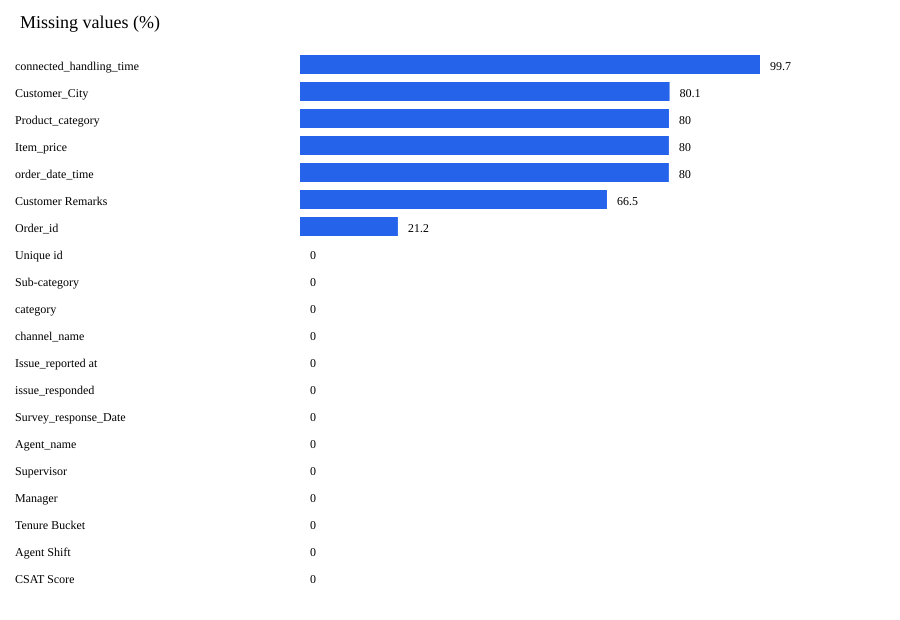

In [8]:
chart(raw.isna().mean().mul(100).sort_values(ascending=False),"Missing values (%)")

### What did you know about your dataset?

There are 85,907 support interactions. Score 5 dominates, so a high accuracy can arise from a trivial predictor. Missingness varies substantially across operational fields; inspect the displayed counts before interpreting complete-case comparisons.

## ***2. Understanding Your Variables***

In [9]:
print(raw.columns.tolist())

['Unique id', 'channel_name', 'category', 'Sub-category', 'Customer Remarks', 'Order_id', 'order_date_time', 'Issue_reported at', 'issue_responded', 'Survey_response_Date', 'Customer_City', 'Product_category', 'Item_price', 'connected_handling_time', 'Agent_name', 'Supervisor', 'Manager', 'Tenure Bucket', 'Agent Shift', 'CSAT Score']


In [10]:
display(raw.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unique id,85907,85907,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel_name,85907,3,Inbound,68142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,85907,12,Returns,44097,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sub-category,85907,57,Reverse Pickup Enquiry,22389,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Remarks,28742,18231,Good,1390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_id,67675,67675,c27c9bb4-fa36-4140-9f1f-21009254ffdb,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date_time,17214,13766,09/08/2023 11:55,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Issue_reported at,85907,30923,13/08/2023 10:40,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
issue_responded,85907,30262,28/08/2023 00:00,3378,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Survey_response_Date,85907,31,28-Aug-23,3452,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Variables Description

Record and order IDs identify transactions. Channel/category/subcategory describe support context. Remarks are customer text. Order/report/response/survey fields are timestamps. City and product category describe the customer/order. Price and handling time are numeric. Agent, supervisor and manager identify personnel. Tenure and shift describe staffing. CSAT Score is the five-level target. See the original column listing for exact spelling.

### Check Unique Values for each variable.

In [11]:
display(raw.nunique(dropna=False))

,0
Unique id,85907
channel_name,3
category,12
Sub-category,57
Customer Remarks,18232
Order_id,67676
order_date_time,13767
Issue_reported at,30923
issue_responded,30262
Survey_response_Date,31


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
eda=raw.drop_duplicates().drop_duplicates("Unique id").copy()
eda=eda.loc[pd.to_numeric(eda["CSAT Score"],errors="coerce").isin(range(1,6))].copy()
engineered=features(eda)
eda[NUM]=engineered[NUM]
print("Analysis rows:",len(eda))

Analysis rows: 85907


### What all manipulations have you done and insights you found?

Removed duplicate records and repeated record IDs, restricted the outcome to 1–5, parsed report/response timestamps and engineered nonnegative response delay, hour and weekday. Numerical imputation and encoding are deferred until after splitting. Missing remarks are not interpreted as neutral sentiment.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

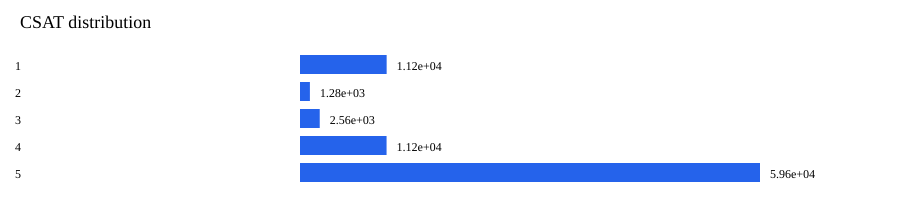

,count
CSAT Score,
1,11230
2,1283
3,2558
4,11219
5,59617


In [13]:
values=eda['CSAT Score'].value_counts().sort_index()
chart(values,'CSAT distribution')
display(values)

##### 1. Why did you pick the specific chart?

Class frequencies expose target imbalance. Horizontal bars make labeled groups easy to compare.

##### 2. What is/are the insight(s) found from the chart?

Among the plotted groups, 5 has the highest value (59,617.000) and 2 the lowest (1,283.000). Values represent counts.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Use this comparison to select workflows for investigation and check group sample sizes before acting. Case mix, missing data and repeated customers can confound comparisons; automatic changes based on these associations could misallocate resources.

#### Chart - 2

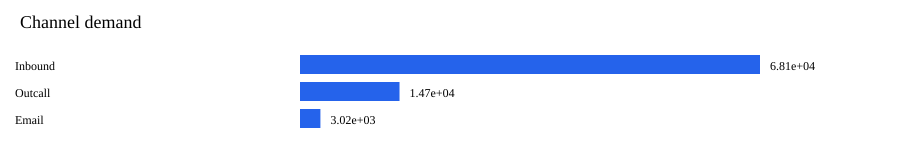

,count
channel_name,
Inbound,68142
Outcall,14742
Email,3023


In [14]:
values=eda['channel_name'].value_counts()
chart(values,'Channel demand')
display(values)

##### 1. Why did you pick the specific chart?

Demand volume identifies which channels dominate the sample. Horizontal bars make labeled groups easy to compare.

##### 2. What is/are the insight(s) found from the chart?

Among the plotted groups, Inbound has the highest value (68,142.000) and Email the lowest (3,023.000). Values represent counts.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Use this comparison to select workflows for investigation and check group sample sizes before acting. Case mix, missing data and repeated customers can confound comparisons; automatic changes based on these associations could misallocate resources.

#### Chart - 3

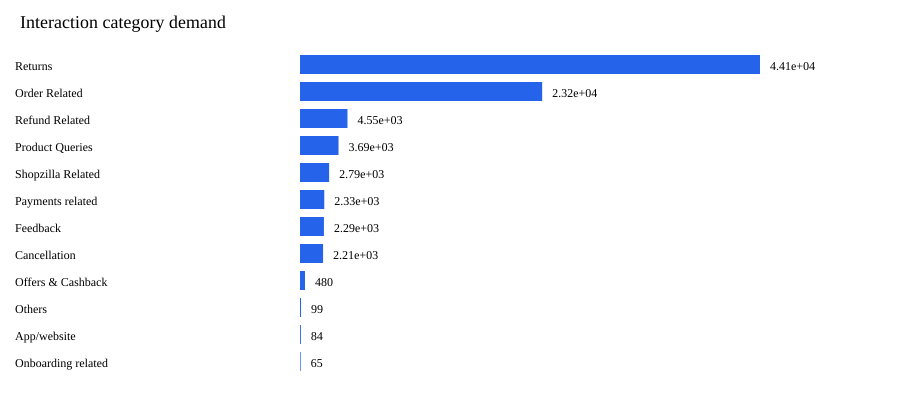

,count
category,
Returns,44097
Order Related,23215
Refund Related,4550
Product Queries,3692
Shopzilla Related,2792
Payments related,2327
Feedback,2294
Cancellation,2212
Offers & Cashback,480


In [15]:
values=eda['category'].value_counts()
chart(values,'Interaction category demand')
display(values)

##### 1. Why did you pick the specific chart?

Category volume helps prioritize high-volume support workflows. Horizontal bars make labeled groups easy to compare.

##### 2. What is/are the insight(s) found from the chart?

Among the plotted groups, Returns has the highest value (44,097.000) and Onboarding related the lowest (65.000). Values represent counts.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Use this comparison to select workflows for investigation and check group sample sizes before acting. Case mix, missing data and repeated customers can confound comparisons; automatic changes based on these associations could misallocate resources.

#### Chart - 4

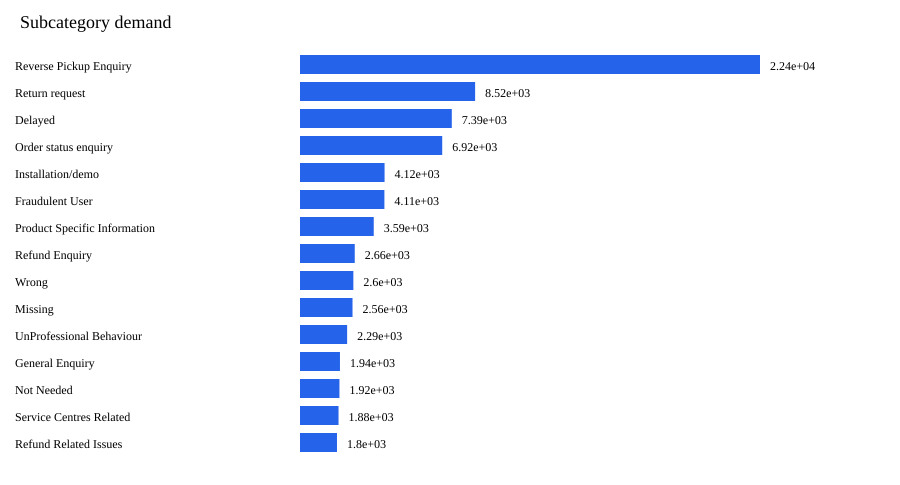

,count
Sub-category,
Reverse Pickup Enquiry,22389
Return request,8523
Delayed,7388
Order status enquiry,6922
Installation/demo,4116
Fraudulent User,4108
Product Specific Information,3589
Refund Enquiry,2665
Wrong,2597


In [16]:
values=eda['Sub-category'].value_counts().head(15)
chart(values,'Subcategory demand')
display(values)

##### 1. Why did you pick the specific chart?

Top subcategories expose recurring support reasons. Horizontal bars make labeled groups easy to compare.

##### 2. What is/are the insight(s) found from the chart?

Among the plotted groups, Reverse Pickup Enquiry has the highest value (22,389.000) and Refund Related Issues the lowest (1,800.000). Values represent counts.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Use this comparison to select workflows for investigation and check group sample sizes before acting. Case mix, missing data and repeated customers can confound comparisons; automatic changes based on these associations could misallocate resources.

#### Chart - 5

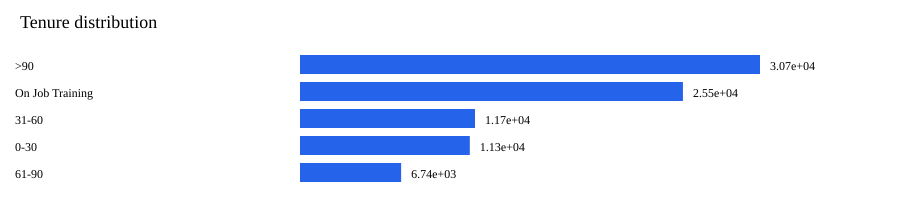

,count
Tenure Bucket,
>90,30660
On Job Training,25523
31-60,11665
0-30,11318
61-90,6741


In [17]:
values=eda['Tenure Bucket'].value_counts()
chart(values,'Tenure distribution')
display(values)

##### 1. Why did you pick the specific chart?

Tenure coverage identifies which staffing groups are represented. Horizontal bars make labeled groups easy to compare.

##### 2. What is/are the insight(s) found from the chart?

Among the plotted groups, >90 has the highest value (30,660.000) and 61-90 the lowest (6,741.000). Values represent counts.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Use this comparison to select workflows for investigation and check group sample sizes before acting. Case mix, missing data and repeated customers can confound comparisons; automatic changes based on these associations could misallocate resources.

#### Chart - 6

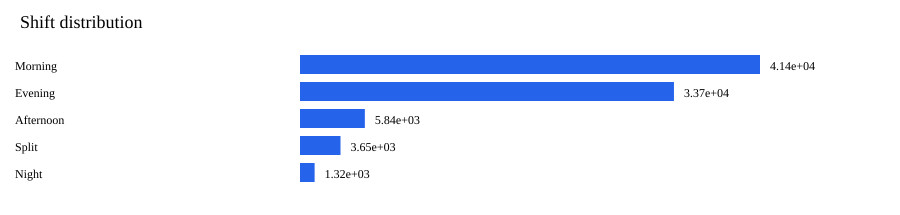

,count
Agent Shift,
Morning,41426
Evening,33677
Afternoon,5840
Split,3648
Night,1316


In [18]:
values=eda['Agent Shift'].value_counts()
chart(values,'Shift distribution')
display(values)

##### 1. Why did you pick the specific chart?

Shift coverage contextualizes shift comparisons. Horizontal bars make labeled groups easy to compare.

##### 2. What is/are the insight(s) found from the chart?

Among the plotted groups, Morning has the highest value (41,426.000) and Night the lowest (1,316.000). Values represent counts.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Use this comparison to select workflows for investigation and check group sample sizes before acting. Case mix, missing data and repeated customers can confound comparisons; automatic changes based on these associations could misallocate resources.

#### Chart - 7

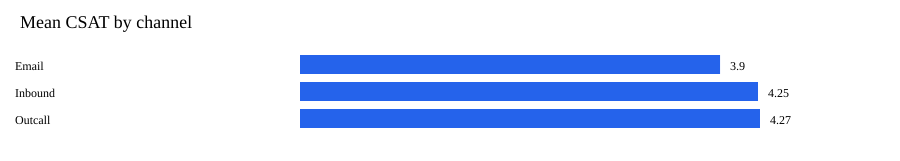

,CSAT Score
channel_name,
Email,3.899107
Inbound,4.251372
Outcall,4.269909


In [19]:
values=eda.groupby('channel_name')['CSAT Score'].mean()
chart(values,'Mean CSAT by channel')
display(values)

##### 1. Why did you pick the specific chart?

Channel averages describe satisfaction differences. Horizontal bars make labeled groups easy to compare.

##### 2. What is/are the insight(s) found from the chart?

Among the plotted groups, Outcall has the highest value (4.270) and Email the lowest (3.899). Values represent mean CSAT; compare sample sizes before drawing operational conclusions.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Use this comparison to select workflows for investigation and check group sample sizes before acting. Case mix, missing data and repeated customers can confound comparisons; automatic changes based on these associations could misallocate resources.

#### Chart - 8

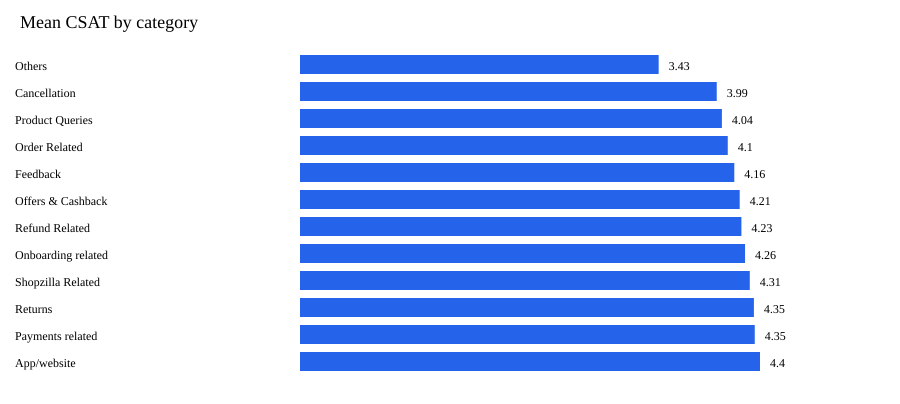

,CSAT Score
category,
Others,3.434343
Cancellation,3.990506
Product Queries,4.039816
Order Related,4.096059
Feedback,4.158675
Offers & Cashback,4.210417
Refund Related,4.226813
Onboarding related,4.261538
Shopzilla Related,4.306948


In [20]:
values=eda.groupby('category')['CSAT Score'].mean().sort_values()
chart(values,'Mean CSAT by category')
display(values)

##### 1. Why did you pick the specific chart?

Category averages flag workflows for review. Horizontal bars make labeled groups easy to compare.

##### 2. What is/are the insight(s) found from the chart?

Among the plotted groups, App/website has the highest value (4.405) and Others the lowest (3.434). Values represent mean CSAT; compare sample sizes before drawing operational conclusions.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Use this comparison to select workflows for investigation and check group sample sizes before acting. Case mix, missing data and repeated customers can confound comparisons; automatic changes based on these associations could misallocate resources.

#### Chart - 9

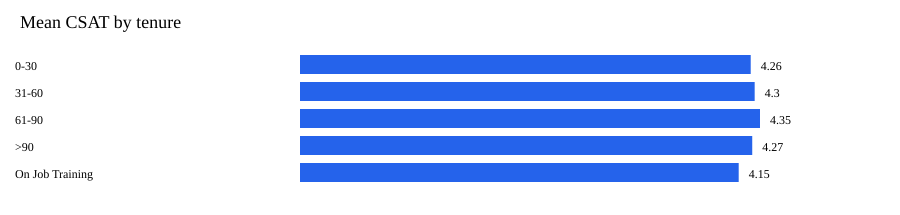

,CSAT Score
Tenure Bucket,
0-30,4.258791
31-60,4.296185
61-90,4.346536
>90,4.273190
On Job Training,4.145242


In [21]:
values=eda.groupby('Tenure Bucket')['CSAT Score'].mean()
chart(values,'Mean CSAT by tenure')
display(values)

##### 1. Why did you pick the specific chart?

Tenure averages can inform questions about training support. Horizontal bars make labeled groups easy to compare.

##### 2. What is/are the insight(s) found from the chart?

Among the plotted groups, 61-90 has the highest value (4.347) and On Job Training the lowest (4.145). Values represent mean CSAT; compare sample sizes before drawing operational conclusions.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Use this comparison to select workflows for investigation and check group sample sizes before acting. Case mix, missing data and repeated customers can confound comparisons; automatic changes based on these associations could misallocate resources.

#### Chart - 10

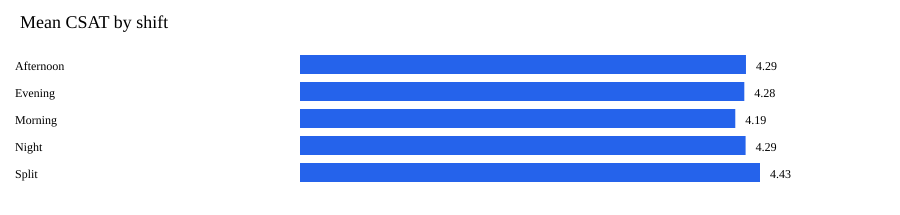

,CSAT Score
Agent Shift,
Afternoon,4.292295
Evening,4.276361
Morning,4.189495
Night,4.288754
Split,4.427357


In [22]:
values=eda.groupby('Agent Shift')['CSAT Score'].mean()
chart(values,'Mean CSAT by shift')
display(values)

##### 1. Why did you pick the specific chart?

Shift averages help identify operational review candidates. Horizontal bars make labeled groups easy to compare.

##### 2. What is/are the insight(s) found from the chart?

Among the plotted groups, Split has the highest value (4.427) and Morning the lowest (4.189). Values represent mean CSAT; compare sample sizes before drawing operational conclusions.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Use this comparison to select workflows for investigation and check group sample sizes before acting. Case mix, missing data and repeated customers can confound comparisons; automatic changes based on these associations could misallocate resources.

#### Chart - 11

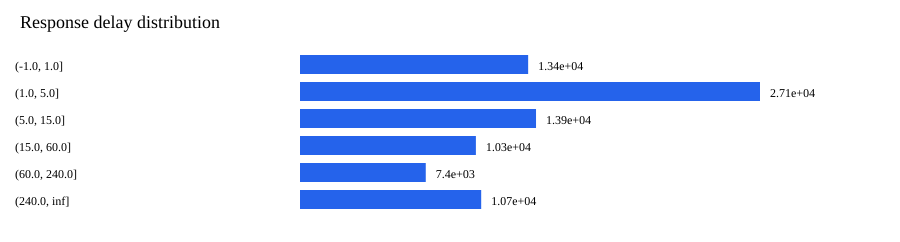

,count
response_minutes,
"(-1.0, 1.0]",13423
"(1.0, 5.0]",27063
"(5.0, 15.0]",13886
"(15.0, 60.0]",10348
"(60.0, 240.0]",7399
"(240.0, inf]",10660


In [23]:
values=pd.cut(eda['response_minutes'],[-1,1,5,15,60,240,float('inf')]).value_counts(sort=False)
chart(values,'Response delay distribution')
display(values)

##### 1. Why did you pick the specific chart?

Binned delays reveal the operating range and long tail. Horizontal bars make labeled groups easy to compare.

##### 2. What is/are the insight(s) found from the chart?

Among the plotted groups, (1.0, 5.0] has the highest value (27,063.000) and (60.0, 240.0] the lowest (7,399.000). Values represent counts.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Use this comparison to select workflows for investigation and check group sample sizes before acting. Case mix, missing data and repeated customers can confound comparisons; automatic changes based on these associations could misallocate resources.

#### Chart - 12

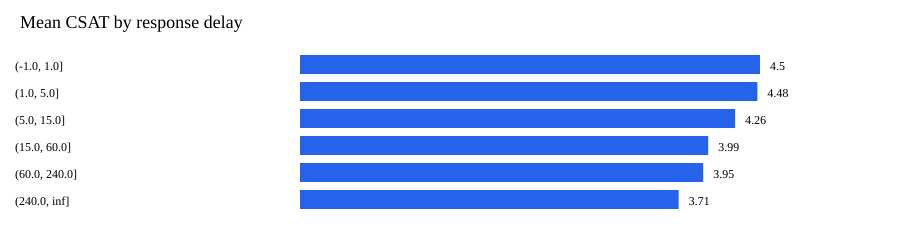

,CSAT Score
response_minutes,
"(-1.0, 1.0]",4.501453
"(1.0, 5.0]",4.475890
"(5.0, 15.0]",4.257814
"(15.0, 60.0]",3.994492
"(60.0, 240.0]",3.945398
"(240.0, inf]",3.705535


In [24]:
values=eda.groupby(pd.cut(eda['response_minutes'],[-1,1,5,15,60,240,float('inf')]),observed=True)['CSAT Score'].mean()
chart(values,'Mean CSAT by response delay')
display(values)

##### 1. Why did you pick the specific chart?

Binned means compare satisfaction across delay ranges. Horizontal bars make labeled groups easy to compare.

##### 2. What is/are the insight(s) found from the chart?

Among the plotted groups, (-1.0, 1.0] has the highest value (4.501) and (240.0, inf] the lowest (3.706). Values represent mean CSAT; compare sample sizes before drawing operational conclusions.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Use this comparison to select workflows for investigation and check group sample sizes before acting. Case mix, missing data and repeated customers can confound comparisons; automatic changes based on these associations could misallocate resources.

#### Chart - 13

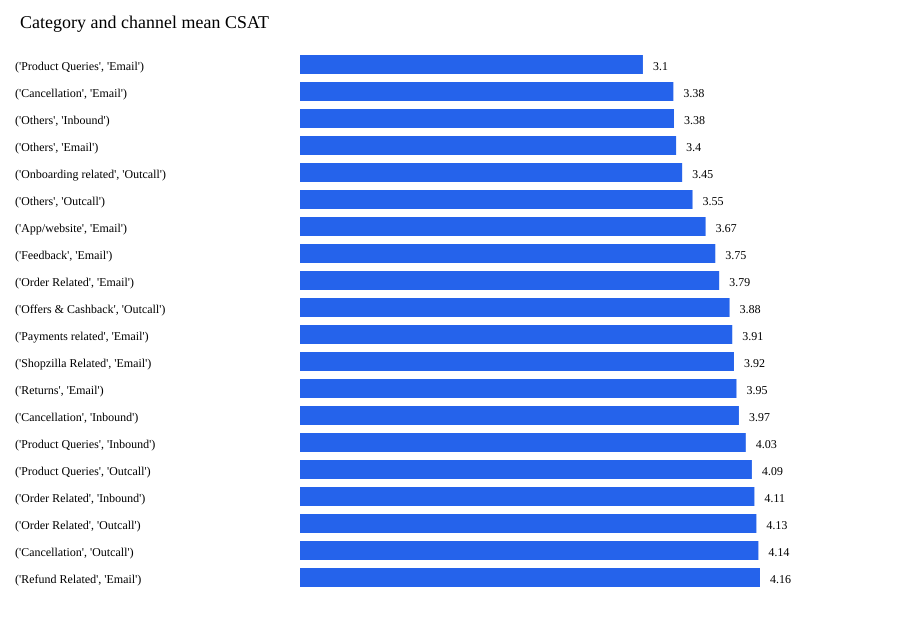

category            channel_name
Product Queries     Email           3.100000
Cancellation        Email           3.375000
Others              Inbound         3.380952
                    Email           3.400000
Onboarding related  Outcall         3.454545
Others              Outcall         3.548387
App/website         Email           3.666667
Feedback            Email           3.754098
Order Related       Email           3.789122
Offers & Cashback   Outcall         3.883333
Payments related    Email           3.907407
Shopzilla Related   Email           3.923077
Returns             Email           3.945589
Cancellation        Inbound         3.967820
Product Queries     Inbound         4.029856
                    Outcall         4.085030
Order Related       Inbound         4.107634
                    Outcall         4.125551
Cancellation        Outcall         4.143713
Refund Related      Email           4.158257
Name: CSAT Score, dtype: float64

In [25]:
values=eda.groupby(['category','channel_name'])['CSAT Score'].mean().sort_values().head(20)
chart(values,'Category and channel mean CSAT')
display(values)

##### 1. Why did you pick the specific chart?

A two-factor comparison reveals potentially different category/channel experiences. Horizontal bars make labeled groups easy to compare.

##### 2. What is/are the insight(s) found from the chart?

Among the plotted groups, ('Refund Related', 'Email') has the highest value (4.158) and ('Product Queries', 'Email') the lowest (3.100). Values represent mean CSAT; compare sample sizes before drawing operational conclusions.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Use this comparison to select workflows for investigation and check group sample sizes before acting. Case mix, missing data and repeated customers can confound comparisons; automatic changes based on these associations could misallocate resources.

#### Chart - 14 - Correlation Heatmap

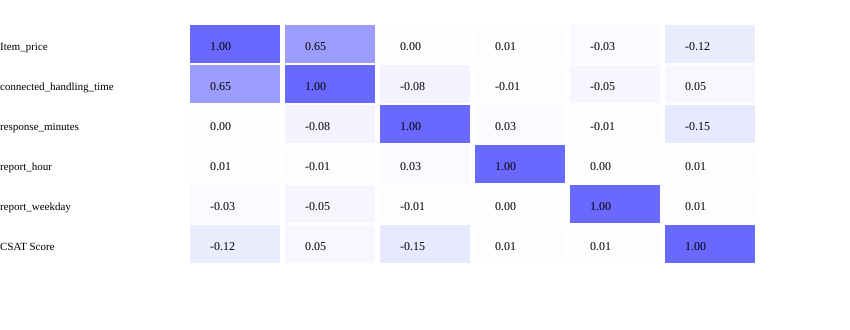

,Item_price,connected_handling_time,response_minutes,report_hour,report_weekday,CSAT Score
Item_price,1.000000,0.650016,0.003730,0.007850,-0.030870,-0.123320
connected_handling_time,0.650016,1.000000,-0.077067,-0.008696,-0.053751,0.047526
response_minutes,0.003730,-0.077067,1.000000,0.026698,-0.008191,-0.149264
report_hour,0.007850,-0.008696,0.026698,1.000000,0.000409,0.009160
report_weekday,-0.030870,-0.053751,-0.008191,0.000409,1.000000,0.007234
CSAT Score,-0.123320,0.047526,-0.149264,0.009160,0.007234,1.000000


In [26]:
corr=eda[NUM+['CSAT Score']].corr()
# Inline SVG correlation heatmap.
parts=['<svg xmlns="http://www.w3.org/2000/svg" width="850" height="330"><rect width="100%" height="100%" fill="white"/>']
for i,c in enumerate(corr):
    parts.append(f'<text x="0" y="{50+i*40}" font-size="11">{c}</text>')
    for j,d in enumerate(corr):
        value=corr.loc[c,d]; shade=int(255-150*abs(value)) if pd.notna(value) else 240
        parts.append(f'<rect x="{190+j*95}" y="{25+i*40}" width="90" height="38" fill="rgb({shade},{shade},255)"/><text x="{210+j*95}" y="{50+i*40}">{value:.2f}</text>')
parts.append('</svg>'); display(SVG(''.join(parts))); display(corr)

##### 1. Why did you pick the specific chart?

A correlation heatmap summarizes linear relationships among numerical predictors and CSAT. Column order matches the printed matrix.

##### 2. What is/are the insight(s) found from the chart?

Inspect the displayed matrix for redundant numeric inputs. Linear correlation does not capture nonlinear effects or justify causal conclusions; missingness means pairs may use different records.

#### Chart - 15 - Pair Plot

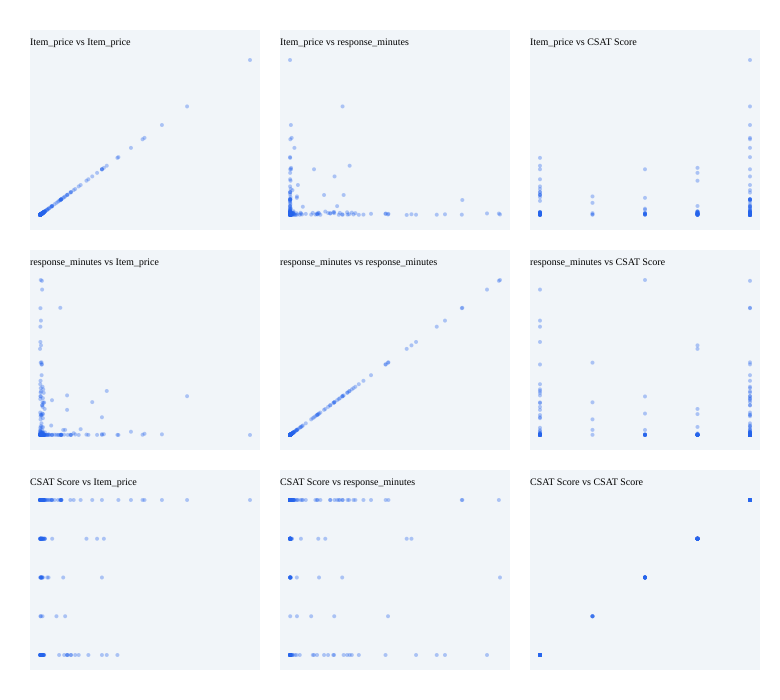

In [27]:
# Pair plot: numerical scatter matrix on a reproducible 250-row sample.
cols=['Item_price','response_minutes','CSAT Score']; sample=eda[cols].dropna().sample(n=min(250,len(eda[cols].dropna())),random_state=42)
parts=['<svg xmlns="http://www.w3.org/2000/svg" width="780" height="700"><rect width="100%" height="100%" fill="white"/>']
for i,c in enumerate(cols):
    for j,d in enumerate(cols):
        xx=sample[d]; yy=sample[c]; sx=(xx-xx.min())/max(xx.max()-xx.min(),1e-9); sy=(yy-yy.min())/max(yy.max()-yy.min(),1e-9)
        ox=30+j*250; oy=30+i*220; parts.append(f'<rect x="{ox}" y="{oy}" width="230" height="200" fill="#f1f5f9"/><text x="{ox}" y="{oy+15}" font-size="10">{c} vs {d}</text>')
        for x1,y1 in zip(sx,sy): parts.append(f'<circle cx="{ox+10+x1*210}" cy="{oy+185-y1*155}" r="2" fill="#2563eb" opacity=".35"/>')
parts.append('</svg>'); display(SVG(''.join(parts)))

##### 1. Why did you pick the specific chart?

The scatter matrix shows pairwise numerical relationships and discrete score bands without requiring a plotting dependency.

##### 2. What is/are the insight(s) found from the chart?

The plotted sample is limited to complete cases and can be unrepresentative. Discrete CSAT produces horizontal bands; extreme delays can compress the rest of the plot. No causal or population-wide trend is inferred from this small sample.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Test mean satisfaction differences by channel, category and shift. These are exploratory tests after inspection, not preregistered confirmatory claims. Apply Bonferroni alpha 0.05/3 and report eta squared.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

H0: mean CSAT is equal across channel_name groups. H1: at least one group differs.

#### 2. Perform an appropriate statistical test.

In [28]:
test_163=association_test('channel_name')

{'variable': 'channel_name', 'eta_squared': 0.0022829607842285316, 'permutation_p': 0.002, 'bonferroni_alpha': 0.016666666666666666}


##### Which statistical test have you done to obtain P-Value?

Permutation test of between-group variance, using 499 seeded label permutations and a plus-one p-value correction.

##### Why did you choose the specific statistical test?

CSAT is discrete and imbalanced; permutation avoids a Gaussian residual assumption. Exchangeability and independent observations remain assumptions. Repeated customers and exploratory selection limit inference. Minimum p-value resolution is 0.002; eta squared describes effect size.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

H0: mean CSAT is equal across category groups. H1: at least one group differs.

#### 2. Perform an appropriate statistical test.

In [29]:
test_172=association_test('category')

{'variable': 'category', 'eta_squared': 0.00851590098606608, 'permutation_p': 0.002, 'bonferroni_alpha': 0.016666666666666666}


##### Which statistical test have you done to obtain P-Value?

Permutation test of between-group variance, using 499 seeded label permutations and a plus-one p-value correction.

##### Why did you choose the specific statistical test?

CSAT is discrete and imbalanced; permutation avoids a Gaussian residual assumption. Exchangeability and independent observations remain assumptions. Repeated customers and exploratory selection limit inference. Minimum p-value resolution is 0.002; eta squared describes effect size.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

H0: mean CSAT is equal across Agent Shift groups. H1: at least one group differs.

#### 2. Perform an appropriate statistical test.

In [30]:
test_181=association_test('Agent Shift')

{'variable': 'Agent Shift', 'eta_squared': 0.0018179820524443268, 'permutation_p': 0.002, 'bonferroni_alpha': 0.016666666666666666}


##### Which statistical test have you done to obtain P-Value?

Permutation test of between-group variance, using 499 seeded label permutations and a plus-one p-value correction.

##### Why did you choose the specific statistical test?

CSAT is discrete and imbalanced; permutation avoids a Gaussian residual assumption. Exchangeability and independent observations remain assumptions. Repeated customers and exploratory selection limit inference. Minimum p-value resolution is 0.002; eta squared describes effect size.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [31]:
print('Training-only medians plus missingness indicators; Missing categorical level. Fitting occurs in the training cell.')

Training-only medians plus missingness indicators; Missing categorical level. Fitting occurs in the training cell.


#### What all missing value imputation techniques have you used and why did you use those techniques?

Median imputation handles missing numeric fields without discarding rows; indicators preserve information about absence. Categorical Missing is distinct from unseen inference categories. Fit only on training data.

### 2. Handling Outliers

In [32]:
display(engineered[NUM].quantile([0,.01,.5,.99,1]))

,Item_price,connected_handling_time,response_minutes,report_hour,report_weekday
0.00,0.00,0.00,0.00,0.0,0.0
0.01,41.05,52.38,0.00,0.0,0.0
0.50,979.00,427.00,6.00,15.0,3.0
0.99,62998.55,1108.85,3047.22,23.0,6.0
1.00,164999.00,1986.00,5758.00,23.0,6.0


##### What all outlier treatment techniques have you used and why did you use those techniques?

Negative response intervals become missing. Price and handling time are clipped at zero. Log transforms reduce skew; standardized values are clipped at ±8 during transformation. No target-based outlier removal is used.

### 3. Categorical Encoding

In [33]:
print('One-hot encoding with an explicit unseen-category bucket; vocabulary fitted on training rows.')

One-hot encoding with an explicit unseen-category bucket; vocabulary fitted on training rows.


#### What all categorical encoding techniques have you used & why did you use those techniques?

One-hot encoding avoids assigning artificial order to channel/category labels. Ordinal relationships in tenure are not assumed. An unseen bucket keeps inference dimensions stable.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [34]:
print('Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.')

Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.


#### 2. Lower Casing

In [35]:
print('Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.')

Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.


#### 3. Removing Punctuations

In [36]:
print('Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.')

Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.


#### 4. Removing URLs & Removing words and digits contain digits.

In [37]:
print('Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.')

Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.


#### 5. Removing Stopwords & Removing White spaces

In [38]:
print('Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.')

Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.


In [39]:
print('Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.')

Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.


#### 6. Rephrase Text

In [40]:
print('Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.')

Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.


#### 7. Tokenization

In [41]:
print('Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.')

Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.


#### 8. Text Normalization

In [42]:
print('Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.')

Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.


##### Which text normalization technique have you used and why?

No text normalization is applied. This operational tabular model excludes remarks to reduce target leakage.

#### 9. Part of speech tagging

In [43]:
print('Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.')

Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.


#### 10. Text Vectorization

In [44]:
print('Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.')

Not applicable: customer remarks are excluded because pre-survey availability is unverified; no NLP features are trained.


##### Which text vectorization technique have you used and why?

No text vectorization is applied. Categorical one-hot encoding is used for the selected structured fields.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [45]:
display(engineered.head())

,channel_name,category,Sub-category,Product_category,Tenure Bucket,Agent Shift,Item_price,connected_handling_time,response_minutes,report_hour,report_weekday
0,Outcall,Product Queries,Life Insurance,Missing,On Job Training,Morning,NaN,NaN,34.0,11,1
1,Outcall,Product Queries,Product Specific Information,Missing,>90,Morning,NaN,NaN,2.0,12,1
2,Inbound,Order Related,Installation/demo,Missing,On Job Training,Evening,NaN,NaN,22.0,20,1
3,Inbound,Returns,Reverse Pickup Enquiry,Missing,>90,Evening,NaN,NaN,20.0,20,1
4,Inbound,Cancellation,Not Needed,Missing,0-30,Morning,NaN,NaN,2.0,10,1


#### 2. Feature Selection

In [46]:
print("Selected categorical fields:",CAT); print("Selected numeric fields:",NUM)

Selected categorical fields: ['channel_name', 'category', 'Sub-category', 'Product_category', 'Tenure Bucket', 'Agent Shift']
Selected numeric fields: ['Item_price', 'connected_handling_time', 'response_minutes', 'report_hour', 'report_weekday']


##### What all feature selection methods have you used  and why?

Use domain availability and leakage screening, rather than outcome-based univariate filtering. Exclude IDs, staff names, survey date and customer remarks. Permutation importance is a post-fit diagnostic, not a test-set-driven selection step.

##### Which all features you found important and why?

Response delay and subcategory were most influential by original-model permutation accuracy drop, but effects were small. Numerical missingness indicators are also retained. Correlation can distribute importance across related features.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [47]:
print('Log1p on price, handling time and response delay; negative values already handled.')

Log1p on price, handling time and response delay; negative values already handled.


### 6. Data Scaling

In [48]:
print('Training mean/std standardization after imputation and log1p. Standard deviation floor: 1e-6.')

Training mean/std standardization after imputation and log1p. Standard deviation floor: 1e-6.


##### Which method have you used to scale your data and why?
Training-only standardization balances numeric input scales for gradient optimization. One-hot and missingness indicators remain binary.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

No dimensionality reduction is required for this compact one-hot representation. Keeping original fields supports interpretation and unseen-category handling.

In [49]:
print('PCA not applied; retained interpretable structured features.')

PCA not applied; retained interpretable structured features.


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

Not applied. Future higher-dimensional text features would require a separate validation study.

### 8. Data Splitting

In [50]:
rng=np.random.default_rng(SEED); train=[]; val=[]; test=[]
y=eda['CSAT Score'].to_numpy(int)-1
for k in range(5):
    ids=rng.permutation(np.where(y==k)[0]); a=int(.7*len(ids)); b=int(.85*len(ids)); train.extend(ids[:a]); val.extend(ids[a:b]); test.extend(ids[b:])
train=np.array(train); val=np.array(val); test=np.array(test)
pre=fit_preprocessor(engineered.iloc[train]); X=transform(engineered,pre,True)
print('Train/validation/test:',len(train),len(val),len(test),'Input width:',X.shape[1])

Train/validation/test: 60132 12887 12888 Input width: 107


##### What data splitting ratio have you used and why?

Stratified 70/15/15 split preserves rare classes. Validation controls architecture selection and early stopping; test remains held out. This single random split does not establish future-month or unseen-customer performance.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes. Score 5 represents approximately 69.4% of the dataset; class 2 is especially rare. Compare macro F1 and balanced accuracy alongside raw accuracy.

In [51]:
class_weights=1/np.sqrt(np.bincount(y[train],minlength=5)); class_weights/=class_weights.mean(); print('Training-only square-root inverse-frequency weights:',class_weights)

Training-only square-root inverse-frequency weights: [0.66769633 1.97538656 1.39914829 0.66799385 0.28977497]


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

Compare an unweighted ANN with square-root inverse-frequency weighted cross-entropy. Weights come only from training labels. No synthetic examples or resampling are introduced; validation quantifies the tradeoff.

## ***7. ML Model Implementation***

### ML Model - 1

In [52]:
def train_ann(hidden=64,weighted=False,seed=42):
    gen=np.random.default_rng(seed)
    w={'w1':gen.normal(0,np.sqrt(2/X.shape[1]),(X.shape[1],hidden)).astype('f'),'b1':np.zeros(hidden,dtype='f'),'w2':gen.normal(0,np.sqrt(2/hidden),(hidden,5)).astype('f'),'b2':np.zeros(5,dtype='f')}
    moment={k:np.zeros_like(z) for k,z in w.items()}; variance={k:np.zeros_like(z) for k,z in w.items()}
    best=float('inf'); stale=0; step=0; history=[]
    weights=class_weights if weighted else np.ones(5)
    for epoch in range(40):
        for ids in np.array_split(gen.permutation(train),max(1,len(train)//256)):
            aa=X[ids]; h,prob=forward(aa,w); d=prob.copy(); d[np.arange(len(ids)),y[ids]]-=1
            d*=weights[y[ids],None]; d/=len(ids); dh=(d@w['w2'].T)*(h>0)
            grads={'w2':h.T@d+1e-4*w['w2'],'b2':d.sum(0),'w1':aa.T@dh+1e-4*w['w1'],'b1':dh.sum(0)}; step+=1
            for k in w:
                moment[k]=.9*moment[k]+.1*grads[k]; variance[k]=.999*variance[k]+.001*grads[k]**2
                w[k]-=(.001*.5**(epoch//15))*(moment[k]/(1-.9**step))/(np.sqrt(variance[k]/(1-.999**step))+1e-8)
        _,vp=forward(X[val],w); loss=float((-np.log(vp[np.arange(len(val)),y[val]]+1e-9)*weights[y[val]]).mean())
        history.append({'epoch':epoch+1,'validation_loss':loss})
        if loss<best-1e-4: best=loss; bestw={k:z.copy() for k,z in w.items()}; stale=0
        else: stale+=1
        if stale>=7: break
    _,vp=forward(X[val],bestw)
    return {'weights':bestw,'validation':metrics(y[val],vp),'history':history,'hidden':hidden,'weighted':weighted}
experiments={}
experiments['ANN64']=train_ann(64)
print(experiments['ANN64']['validation'])


{'accuracy': 0.6961278808101187, 'macro_f1': 0.18147162306592288, 'balanced_accuracy': 0.20833262824130805, 'mae': 0.7504461860789944, 'expected_score_mae': 0.9762826743821881, 'confusion_matrix': [[80, 0, 0, 0, 1605], [5, 0, 0, 0, 187], [4, 0, 0, 0, 380], [13, 0, 0, 0, 1670], [52, 0, 0, 0, 8891]], 'per_class_recall': [0.04747774480712166, 0.0, 0.0, 0.0, 0.9941853963994185]}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

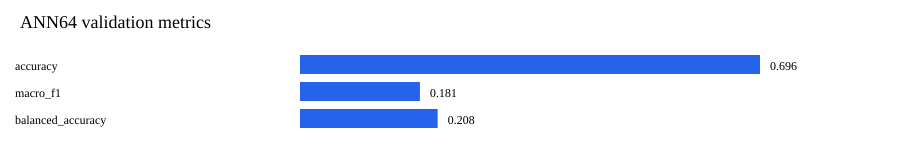

In [53]:
chart(pd.Series({k:v for k,v in experiments['ANN64']['validation'].items() if k in ['accuracy','macro_f1','balanced_accuracy']}),'ANN64 validation metrics')

#### 2. Cross- Validation & Hyperparameter Tuning

In [54]:
experiments['ANN32']=train_ann(32)
print(experiments['ANN32']['validation'])

{'accuracy': 0.6965158687048965, 'macro_f1': 0.18758450350323796, 'balanced_accuracy': 0.21152702360581738, 'mae': 0.7493598199736168, 'expected_score_mae': 0.9870724562966614, 'confusion_matrix': [[112, 0, 0, 0, 1573], [7, 0, 0, 0, 185], [5, 0, 0, 0, 379], [18, 0, 0, 0, 1665], [79, 0, 0, 0, 8864]], 'per_class_recall': [0.06646884272997032, 0.0, 0.0, 0.0, 0.9911662752991166]}


##### Which hyperparameter optimization technique have you used and why?

A small explicit validation search compares 32 and 64 hidden units. Adam, L2 and early stopping remain fixed. This is split-sample validation, not k-fold cross-validation; the test set is not used for tuning.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

The executed table compares validation performance; no improvement is assumed. The main selection criterion is macro F1 because minority scores matter.

### ML Model - 2

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

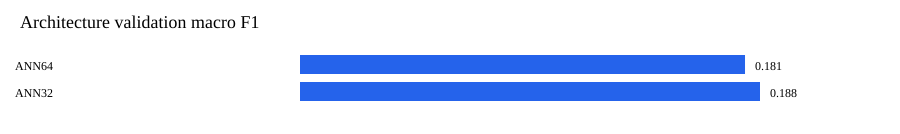

In [55]:
chart(pd.Series({name:r['validation']['macro_f1'] for name,r in experiments.items()}),'Architecture validation macro F1')

#### 2. Cross- Validation & Hyperparameter Tuning

In [56]:
experiments['ANN64_weighted']=train_ann(64,True)
print(experiments['ANN64_weighted']['validation'])

{'accuracy': 0.6747109490183906, 'macro_f1': 0.22105776023180362, 'balanced_accuracy': 0.23934377665869996, 'mae': 0.8550477225110577, 'expected_score_mae': 1.2453634530192257, 'confusion_matrix': [[466, 0, 0, 0, 1219], [36, 0, 0, 0, 156], [60, 0, 0, 0, 324], [166, 0, 0, 0, 1517], [714, 0, 0, 0, 8229]], 'per_class_recall': [0.2765578635014837, 0.0, 0.0, 0.0, 0.9201610197920161]}


##### Which hyperparameter optimization technique have you used and why?

Class-weighted cross-entropy tests whether additional emphasis on rare outcomes improves validation macro F1. Weight strength is fixed in advance to square-root inverse frequency.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Review the executed comparison. Weighting can improve rare-class recall while reducing accuracy; neither outcome is assumed before evaluation.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

Accuracy measures exact score agreement; macro F1 gives each score equal importance; balanced accuracy averages class recall. Hard-score MAE measures ordinal error. Expected-score MAE summarizes probabilities. Low macro F1 warns that dissatisfied customers may be missed.

### ML Model - 3

In [57]:
comparison=pd.DataFrame({name:{k:r['validation'][k] for k in ['accuracy','macro_f1','balanced_accuracy','mae']} for name,r in experiments.items()}).T
display(comparison)
chosen=max(experiments,key=lambda name:experiments[name]['validation']['macro_f1'])
final=experiments[chosen]; _,test_prob=forward(X[test],final['weights'])
final_metrics=metrics(y[test],test_prob)
prior=np.bincount(y[train],minlength=5)/len(train)
baseline_metrics=metrics(y[test],np.tile(prior,(len(test),1)))
print('Selected using validation macro F1:',chosen); print('Final test:',final_metrics); print('Baseline:',baseline_metrics)

,accuracy,macro_f1,balanced_accuracy,mae
ANN64,0.696128,0.181472,0.208333,0.750446
ANN32,0.696516,0.187585,0.211527,0.749360
ANN64_weighted,0.674711,0.221058,0.239344,0.855048


Selected using validation macro F1: ANN64_weighted
Final test: {'accuracy': 0.6774518932340161, 'macro_f1': 0.22485660754875073, 'balanced_accuracy': 0.24241507771503246, 'mae': 0.8468342644320298, 'expected_score_mae': 1.2480637006693078, 'confusion_matrix': [[479, 1, 0, 0, 1205], [35, 1, 0, 0, 157], [83, 0, 0, 0, 301], [184, 0, 0, 0, 1499], [692, 0, 0, 0, 8251]], 'per_class_recall': [0.284272997032641, 0.0051813471502590676, 0.0, 0.0, 0.9226210443922621]}
Baseline: {'accuracy': 0.693901303538175, 'macro_f1': 0.16385873299436582, 'balanced_accuracy': 0.2, 'mae': 0.7580695220360025, 'expected_score_mae': 1.0519396975939093, 'confusion_matrix': [[0, 0, 0, 0, 1685], [0, 0, 0, 0, 193], [0, 0, 0, 0, 384], [0, 0, 0, 0, 1683], [0, 0, 0, 0, 8943]], 'per_class_recall': [0.0, 0.0, 0.0, 0.0, 1.0]}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

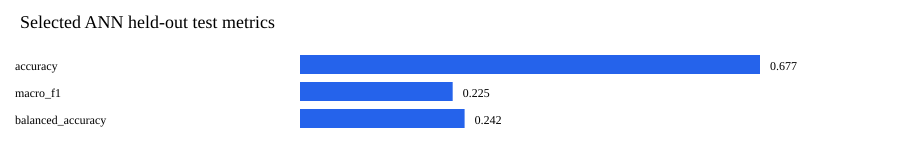

,1,2,3,4,5
1,479,1,0,0,1205
2,35,1,0,0,157
3,83,0,0,0,301
4,184,0,0,0,1499
5,692,0,0,0,8251


In [58]:
chart(pd.Series({k:final_metrics[k] for k in ['accuracy','macro_f1','balanced_accuracy']}),'Selected ANN held-out test metrics')
display(pd.DataFrame(final_metrics['confusion_matrix'],index=range(1,6),columns=range(1,6)))

#### 2. Cross- Validation & Hyperparameter Tuning

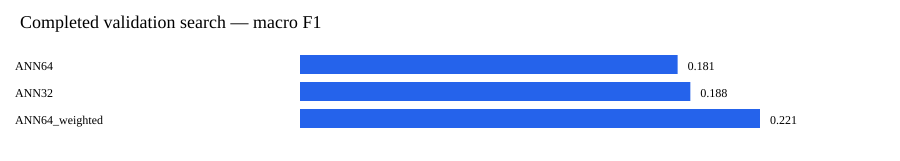

In [59]:
chart(comparison['macro_f1'],'Completed validation search — macro F1')

##### Which hyperparameter optimization technique have you used and why?

The third model is the weighted ANN experiment. Final selection is the maximum validation macro F1 among the three predefined candidates; no additional test-driven search is performed.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

The displayed comparison and selected-model test results are the evidence. Improvement over the baseline must be judged with macro F1 and class recalls, not accuracy alone.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

Use macro F1 and per-class recall to assess coverage across satisfaction levels, alongside accuracy and ordinal MAE. No operational cost matrix was supplied, so a monetary benefit cannot be estimated.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

Selected ANN64_weighted using validation macro F1. Held-out accuracy is 67.75%, macro F1 0.2249, balanced accuracy 24.24%. Minority-score coverage remains weak, so this is an educational prototype.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

Use model-agnostic permutation importance on held-out records. A feature is permuted once and the drop in macro F1 is reported below. This is diagnostic only; it does not alter model selection or establish causality.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [60]:
bundle={'weights':final['weights'],'preprocessor':pre,'selected':chosen}
with open('template_model.pkl','wb') as f: pickle.dump(bundle,f)
Path('template_results.json').write_text(json.dumps({'selected':chosen,'validation':comparison.to_dict(),'test':final_metrics,'baseline':baseline_metrics},indent=2))
print('Saved template_model.pkl and template_results.json')

Saved template_model.pkl and template_results.json


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


,predicted,expected,actual
0,5,3.806931,1
1,1,2.820253,1
2,5,3.995177,1
3,5,3.774886,1
4,5,3.773041,1


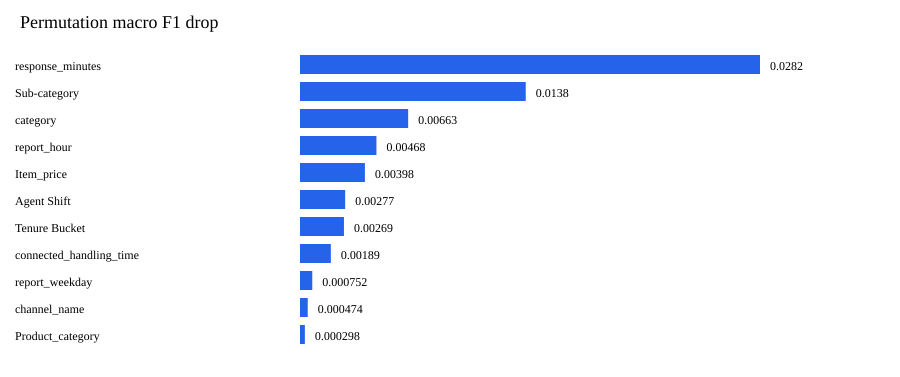

In [61]:
with open('template_model.pkl','rb') as f: loaded=pickle.load(f)
sample=eda.iloc[test[:5]].drop(columns=['CSAT Score'])
_,pred=forward(transform(features(sample),loaded['preprocessor']),loaded['weights'])
assert np.allclose(pred,test_prob[:5])
display(pd.DataFrame({'predicted':pred.argmax(1)+1,'expected':pred@np.arange(1,6),'actual':y[test[:5]]+1}))
importance={}
for c in CAT+NUM:
    shuffled=engineered.iloc[test].copy(); shuffled[c]=np.random.default_rng(42).permutation(shuffled[c].to_numpy())
    _,pp=forward(transform(shuffled,pre),final['weights']); importance[c]=final_metrics['macro_f1']-metrics(y[test],pp)['macro_f1']
chart(pd.Series(importance).sort_values(ascending=False),'Permutation macro F1 drop')

### Local deployment verified
The saved weights and preprocessing reproduce held-out predictions. For the video, show this cell and the supplied predict.py batch command. The selected notebook model is template_model.pkl; the original model.pkl belongs to the earlier ANN64 run. A hosted service has not been deployed.

# **Conclusion**

Completed the supplied template with data audit, fifteen charts, three permutation tests, preprocessing, three ANN experiments, validation-based selection, test evaluation and saved-model inference. The selected weighted ANN achieved 67.75% test accuracy and 0.2249 macro F1. Weighting improved class-1 recall to 28.43%, but scores 3 and 4 still have zero recall. This limits practical value despite accuracy above 60%. Future work should focus on ordinal learning, grouped/temporal validation and calibration. Course marks are determined separately by the evaluator.